I loaded the file with read_csv() and then inspected head(), shape and info(). I also looked for rows that matched all columns. And there is no exact duplicates


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset from project folder
df = pd.read_csv("olympics_08_medalists.csv")



In [2]:
# overview
print(df.head())
print(df.shape)
df.info()

# Clean gender and sport because they are combined in column names such as male_archery, convert the columns from wide to long.
df_clean = df.drop_duplicates()



       medalist_name male_archery female_archery male_athletics  \
0    Aaron Armstrong          NaN            NaN           gold   
1      Aaron Peirsol          NaN            NaN            NaN   
2   Abdullo Tangriev          NaN            NaN            NaN   
3  Abeer Abdelrahman          NaN            NaN            NaN   
4            Abhinav          NaN            NaN            NaN   

  female_athletics male_badminton female_badminton male_baseball  \
0              NaN            NaN              NaN           NaN   
1              NaN            NaN              NaN           NaN   
2              NaN            NaN              NaN           NaN   
3              NaN            NaN              NaN           NaN   
4              NaN            NaN              NaN           NaN   

  male_basketball female_basketball  ... female_beach volleyball  \
0             NaN               NaN  ...                     NaN   
1             NaN               NaN  ...            

I then used pd.melt(). I kept medalist_name and moved the other column labels into Gender_Sport. The medal values went into Medal. At this stage the long table was full of blanks. These are not additional medalist records, just empty cells in the original file. I dropped rows that had a missing Medal instead of replacing the blanks with zeros.

Gender and sport are combined in headings such as male_archery. Moving these labels into rows makes it possible to separate the two variables for analysis.


In [3]:
df_melted = pd.melt(df_clean,
                    id_vars = ["medalist_name"],
                    var_name = "Gender_Sport",
                    value_name = "Medal")

print("\nMelted Olympic Medalists DataFrame:")
print(df_melted)

# Remove empty rowsthat do not contain a recorded medal
# Missing medal categories should not be replaced with a numeric zero
df_melted.dropna(subset = ["Medal"], inplace = True)
print(df_melted.shape)




Melted Olympic Medalists DataFrame:
            medalist_name                Gender_Sport Medal
0         Aaron Armstrong                male_archery   NaN
1           Aaron Peirsol                male_archery   NaN
2        Abdullo Tangriev                male_archery   NaN
3       Abeer Abdelrahman                male_archery   NaN
4                 Abhinav                male_archery   NaN
...                   ...                         ...   ...
131245        Éver Banega  male_greco-roman wrestling   NaN
131246  Ólafur Stefánsson  male_greco-roman wrestling   NaN
131247      Óscar Brayson  male_greco-roman wrestling   NaN
131248   Łukasz Pawłowski  male_greco-roman wrestling   NaN
131249        Živko Gocić  male_greco-roman wrestling   NaN

[131250 rows x 3 columns]
(1875, 3)


I used str.split() to split Gender_Sport. That gave me Gender and Sport. Next I replaced hyphens with spaces, renamed the name column to Medalist_Name, and sorted the records. I kept Medalist_Name, Gender, Sport, and Medal.
Separating gender and sport gives each variable its own column. 


In [4]:
# Split it into separate gender and sport columns
df_melted[["Gender", "Sport"]] = df_melted["Gender_Sport"].str.split("_", expand = True)
print(df_melted)

# Replace "-" with " " to make sport labels more readable
df_melted["Sport"] = df_melted["Sport"].str.replace("-", " ")
print(df_melted)

# Rename the name column, and sort the records
df_tidy = (df_melted[["medalist_name", "Gender", "Sport", "Medal"]]
           .rename(columns = {"medalist_name": "Medalist_Name"})
           .sort_values(by = ["Sport", "Gender", "Medalist_Name"],
                        ignore_index = True)
           )



              medalist_name                Gender_Sport   Medal Gender  \
177            Bair Badënov                male_archery  bronze   male   
676           Ilario Di Buò                male_archery  silver   male   
682            Im Dong-hyun                male_archery    gold   male   
760               Jiang Lin                male_archery  bronze   male   
920          Lee Chang-hwan                male_archery    gold   male   
...                     ...                         ...     ...    ...   
130932        Steeve Guénot  male_greco-roman wrestling    gold   male   
131159  Yannick Szczepaniak  male_greco-roman wrestling  bronze   male   
131162       Yavor Yanakiev  male_greco-roman wrestling  bronze   male   
131200      Yury Patrikeyev  male_greco-roman wrestling  bronze   male   
131234         Zoltán Fodor  male_greco-roman wrestling  silver   male   

                        Sport  
177                   archery  
676                   archery  
682            

I check the shape, non-null counts, and category counts

In [5]:
# Check the structure and categories after cleaning
print("\nTidy Olympic Medalists DataFrame:")
print(df_tidy.head())
print("Tidy shape:", df_tidy.shape)
df_tidy.info()

print("\nMedal category counts:")
print(df_tidy["Medal"].value_counts())

print("\nGender counts:")
print(df_tidy["Gender"].value_counts())






Tidy Olympic Medalists DataFrame:
     Medalist_Name  Gender    Sport   Medal
0  Bérengère Schuh  female  archery  bronze
1        Chen Ling  female  archery  silver
2          Guo Dan  female  archery  silver
3    Joo Hyun-Jung  female  archery    gold
4   Park Sung-hyun  female  archery  silver
Tidy shape: (1875, 4)
<class 'pandas.DataFrame'>
RangeIndex: 1875 entries, 0 to 1874
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Medalist_Name  1875 non-null   str  
 1   Gender         1875 non-null   str  
 2   Sport          1875 non-null   str  
 3   Medal          1875 non-null   str  
dtypes: str(4)
memory usage: 124.6 KB

Medal category counts:
Medal
bronze    668
silver    621
gold      586
Name: count, dtype: int64

Gender counts:
Gender
male      1032
female     843
Name: count, dtype: int64


This gives us 1,875 records but with four columns and no missing values. Each column is a variable and each row is an observation. This is the format described in Tidy Data paper. It also allows me to group the records directly by Sport or Gender.


I created two pivot tables with count. The first counts medalist records for each sport and gender. The other counts medal categories by gender. 
Count is appropriate here because the values are medal categories rather than numeric measurements.


In [6]:
# Count medalist records for each sport and gender using pivot table
pivot_table_sport = pd.pivot_table(df_tidy,
                                  index = "Sport",
                                  columns = "Gender",
                                  values = "Medal",
                                  aggfunc = "count"
                                  )

# Fill missing summary combinations with zero recorded observations.
pivot_table_sport = pivot_table_sport.fillna(0)
print("\nMedalist Records by Sport and Gender:")
print(pivot_table_sport)

# Count each medal category for female and male records.
pivot_table_medal = pd.pivot_table(df_tidy,
                                  index = "Gender",
                                  columns = "Medal",
                                  values = "Medalist_Name",
                                  aggfunc = "count"
                                  )

pivot_table_medal = pivot_table_medal.fillna(0)
print("\nMedalist Records by Gender and Medal Category:")
print(pivot_table_medal)




Medalist Records by Sport and Gender:
Gender                 female  male
Sport                              
archery                   9.0  11.0
artistic gymnastics      20.0  29.0
association football     54.0  55.0
athletics                81.0  85.0
badminton                10.0  12.0
baseball                  0.0  72.0
basketball               36.0  35.0
beach volleyball          6.0   6.0
bmx                       3.0   3.0
boxing                    0.0  44.0
canoeing and kayaking    21.0  53.0
diving                   13.0  16.0
equestrian sport         20.0  18.0
fencing                  26.0  28.0
field hockey             48.0  50.0
freestyle wrestling      16.0  28.0
greco roman wrestling     0.0  27.0
handball                 42.0  43.0
judo                     28.0  28.0
modern pentathlon         2.0   3.0
mountain biking           3.0   3.0
rhythmic gymnastics      21.0   0.0
road bicycle racing       6.0   5.0
rowing                   58.0  83.0
sailing                  

I sorted the first summary by female counts and plotted the first five rows as a heatmap.

The heatmap places female and male counts side by side for the same sports. Keeping only five sports makes the comparison easier to read.


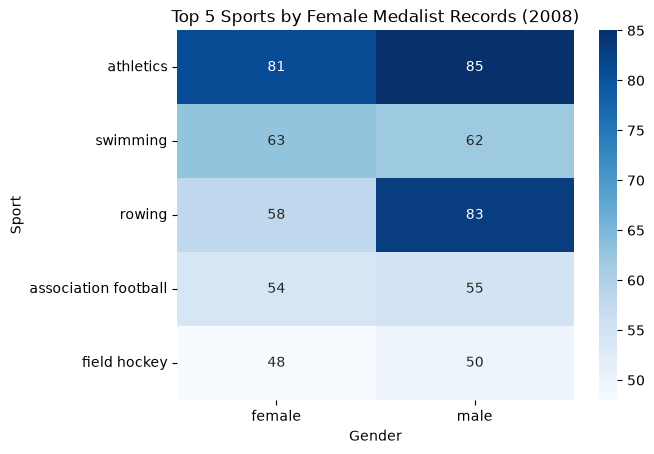

In [7]:
# Find the five sports with the most female medalist records.
pivot_table_sport.sort_values(by = "female",
                             ascending = False,
                             inplace = True
                             )

# Compare female and male records within those five sports.
sns.heatmap(pivot_table_sport.head(), annot = True, fmt = '.0f', cmap = 'Blues')
plt.title('Top 5 Sports by Female Medalist Records (2008)')
plt.xlabel('Gender')
plt.ylabel('Sport')
plt.show()



Athletics has 81 female records, followed by swimming with 63 and rowing with 58. The other two sports shown are association football and field hockey. In swimming, the gender gap is close with 62 male records to 63 for females. In rowing, the gap is wider: 83 men’s records, 58 women’s.


The second heatmap is using the full set of retained records.

This heatmap compares gold, silver, and bronze counts within each gender using the second pivot table.


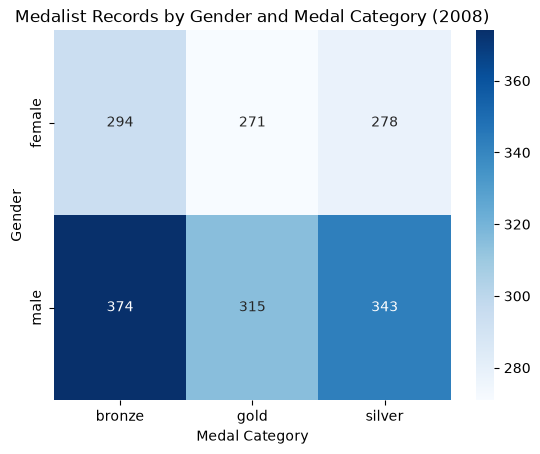

In [8]:
# Compare medal categories by gender using all retained records.
sns.heatmap(pivot_table_medal, annot = True, fmt = '.0f', cmap = 'Blues')
plt.title('Medalist Records by Gender and Medal Category (2008)')
plt.xlabel('Medal Category')
plt.ylabel('Gender')
plt.show()


Bronze has the highest count for both genders: 294 female and 374 male records. All medal categories combined have 843 female records and 1,032 male records.
